# Práctica: Bit Rate Control

### Experimento 1. Which data-ordering performs better?
**Enunciado:** Determine empirically which ordering of the chunk data is the most efficient from a lossless data compression point of view (the smaller the bit-rates, the higher the compression). Use the audio sequence you want. Notice that using different audio files you could obtain different results.

#### Comando boom
```pip install soundfile librosa matplotlib numpy```

In [ ]:
import numpy as np
import zlib
import librosa

#CONFIGURACIÓN Y CARGA DE AUDIO

AUDIO_PATH = "./data/FrancoBattiato_LombraDellaLuce.oga" 

# Cargar audio estéreo manteniendo la frecuencia original
audio_signal, sr = librosa.load(AUDIO_PATH, sr=None, mono=False)

# Garantizar que la señal tenga 2 canales (estéreo)
if audio_signal.ndim == 1:
    audio_signal = np.vstack([audio_signal, audio_signal])

# Convertir float32 (-1.0 a 1.0) a PCM int16
pcm_data = (audio_signal * 32767).astype(np.int16).T
total_samples = len(pcm_data)
duration_sec = total_samples / sr

print(f"Audio cargado: {total_samples} muestras | Frecuencia: {sr} Hz | Duración: {duration_sec:.2f} s\n")




CHUNK_SIZE = 1024  # Muestras por chunk (por canal)
num_chunks = len(pcm_data) // CHUNK_SIZE

bytes_raw = 0
bytes_serial = 0
bytes_byteplanes2 = 0

for i in range(num_chunks):
    chunk = pcm_data[i * CHUNK_SIZE : (i + 1) * CHUNK_SIZE]
    
    # 1. DEFLATE_raw: Muestras entrelazadas originales
    raw_b = chunk.tobytes()
    bytes_raw += len(zlib.compress(raw_b))
    
    # 2. DEFLATE_serial: Desentrelazado de canales (Canal L + Canal R)
    left_ch = chunk[:, 0]
    right_ch = chunk[:, 1]
    serial_b = left_ch.tobytes() + right_ch.tobytes()
    bytes_serial += len(zlib.compress(serial_b))
    
    # 3. DEFLATE_byteplanes2: Desentrelazado + Separación en planos LSB y MSB
    arr_uint8 = np.frombuffer(serial_b, dtype=np.uint8)
    lsb = arr_uint8[0::2].tobytes()
    msb = arr_uint8[1::2].tobytes()
    bytes_byteplanes2 += len(zlib.compress(msb)) + len(zlib.compress(lsb))

# Cálculo del Bit-Rate resultante en kbps
bitrate_raw = (bytes_raw * 8) / duration_sec / 1000
bitrate_serial = (bytes_serial * 8) / duration_sec / 1000
bitrate_byteplanes2 = (bytes_byteplanes2 * 8) / duration_sec / 1000

print("=" * 65)
print(" RESULTADOS EJERCICIO 1: COMPRESIÓN SEGÚN ORDENACIÓN DE DATOS")
print("=" * 65)
print(f"1. DEFLATE_raw:         {bytes_raw:10d} bytes | Bit-rate: {bitrate_raw:7.2f} kbps")
print(f"2. DEFLATE_serial:      {bytes_serial:10d} bytes | Bit-rate: {bitrate_serial:7.2f} kbps")
print(f"3. DEFLATE_byteplanes2: {bytes_byteplanes2:10d} bytes | Bit-rate: {bitrate_byteplanes2:7.2f} kbps")
print("=" * 65)

Audio cargado: 14293647 muestras | Frecuencia: 48000 Hz | Duración: 297.78 s

 RESULTADOS EJERCICIO 1: COMPRESIÓN SEGÚN ORDENACIÓN DE DATOS
1. DEFLATE_raw:           51510202 bytes | Bit-rate: 1383.83 kbps
2. DEFLATE_serial:        51347677 bytes | Bit-rate: 1379.46 kbps
3. DEFLATE_byteplanes2:   41206158 bytes | Bit-rate: 1107.01 kbps


### Experimento 2. Which BR control algorithm shows the best RD (Rate/Distortion) curve?
**Enunciado:** Considering the RMSE (Root Mean Square Error) as a distortion measure between the sent and the received audio signal, for a concrete audio sequence, generate the RD curve considering a set of different simulated transmission environments (use tc or a any other similar tool). Remember that the X-axis must express bit-rate and the Y-axis, distortion.

Simulando BR Control para: ./data/FrancoBattiato_LombraDellaLuce.oga...
Simulando BR Control para: ./data/Metallica_Orion.mp3...
Simulando BR Control para: ./data/VVV_InviernoNuclear.oga...


C:\Users\rocio\AppData\Local\Temp\ipykernel_14700\4047016920.py:101: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean((pcm_data[:len(reconstructed_signal)] - reconstructed_signal) ** 2))


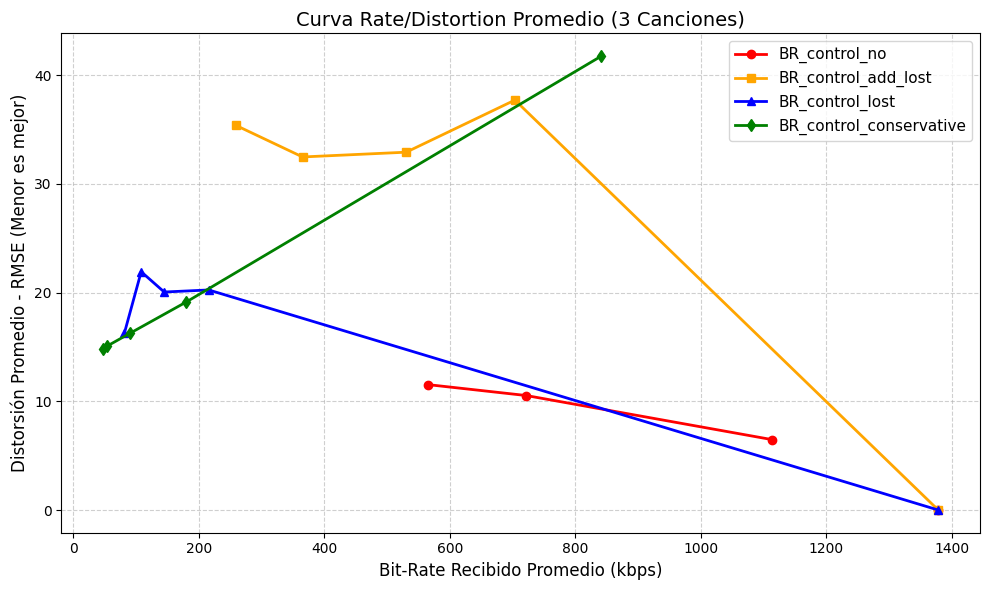

In [ ]:
import os
import zlib
import numpy as np
import librosa
import matplotlib.pyplot as plt

# ==============================================================================
# 0. CONFIGURACIÓN Y LISTA DE CANCIONES (3 MÍNIMO)
# ==============================================================================
AUDIO_FILES = [
    "./data/FrancoBattiato_LombraDellaLuce.oga",
    "./data/Metallica_Orion.mp3",
    "./data/VVV_InviernoNuclear.oga"
]

CHUNK_SIZE = 1024
MAX_DELTA = 32767

def quantize(chunk, delta): 
    if delta <= 1:
        return chunk
    chunk_int32 = chunk.astype(np.int32)
    q_chunk = np.sign(chunk_int32) * (np.abs(chunk_int32) // delta)
    return q_chunk.astype(np.int16)

def dequantize(q_chunk, delta):
    if delta <= 1:
        return q_chunk
    q_int32 = q_chunk.astype(np.int32)
    deq = np.clip(q_int32 * delta, -32768, 32767)
    return deq.astype(np.int16)

network_scenarios = [0, 2, 5, 12, 25]
algorithms = ["BR_control_no", "BR_control_add_lost", "BR_control_lost", "BR_control_conservative"]

# Acumuladores de resultados por algoritmo y escenario
global_results = {algo: {n_lost: {"bitrates": [], "rmses": []} for n_lost in network_scenarios} for algo in algorithms}

# ==============================================================================
# PROCESAMIENTO DE LAS 3 CANCIONES
# ==============================================================================
for file_path in AUDIO_FILES:
    if not os.path.exists(file_path):
        print(f"⚠️ Archivo no encontrado: {file_path}. Saltando...")
        continue
        
    print(f"Simulando BR Control para: {file_path}...")
    audio_signal, sr = librosa.load(file_path, sr=None, mono=False)
    
    if audio_signal.ndim == 1:
        audio_signal = np.vstack([audio_signal, audio_signal])

    pcm_data = (audio_signal * 32767).astype(np.int16).T
    total_samples = len(pcm_data)
    duration_sec = total_samples / sr
    num_chunks = total_samples // CHUNK_SIZE
    chunks_per_sec = int(sr / CHUNK_SIZE)

    for algo in algorithms:
        for n_lost in network_scenarios:
            delta = 1
            total_received_bytes = 0
            reconstructed_chunks = []
            
            for i in range(num_chunks):
                original_chunk = pcm_data[i * CHUNK_SIZE : (i + 1) * CHUNK_SIZE]
                
                # Actualizar Delta cada segundo simulado
                if i > 0 and i % chunks_per_sec == 0:
                    if algo == "BR_control_no":
                        delta = delta
                    elif algo == "BR_control_add_lost":
                        delta = delta + n_lost
                    elif algo == "BR_control_lost":
                        delta = int(delta * (1 + n_lost))
                    elif algo == "BR_control_conservative":
                        factor = 2 ** min(n_lost, 14)
                        delta = max(int(delta * factor), delta + 1)
                    
                    delta = int(np.clip(delta, 1, MAX_DELTA))
                
                # 1. Cuantificación y compresión
                q_chunk = quantize(original_chunk, delta)
                left_q = q_chunk[:, 0].tobytes()
                right_q = q_chunk[:, 1].tobytes()
                compressed_pkt = zlib.compress(left_q + right_q)
                
                # 2. Simulación de transmisión
                loss_prob = min(0.6, (n_lost * 0.04) if algo == "BR_control_no" else (n_lost * 0.005))
                pkt_lost = np.random.rand() < loss_prob
                
                if not pkt_lost:
                    total_received_bytes += len(compressed_pkt)
                    rec_q_chunk = dequantize(q_chunk, delta)
                else:
                    rec_q_chunk = np.zeros_like(original_chunk)
                    
                reconstructed_chunks.append(rec_q_chunk)
                
            reconstructed_signal = np.vstack(reconstructed_chunks)
            rmse = np.sqrt(np.mean((pcm_data[:len(reconstructed_signal)] - reconstructed_signal) ** 2))
            received_bitrate = (total_received_bytes * 8) / duration_sec / 1000
            
            global_results[algo][n_lost]["bitrates"].append(received_bitrate)
            global_results[algo][n_lost]["rmses"].append(rmse)

# ==============================================================================
# GENERACIÓN DE LA GRÁFICA PROMEDIO RATE/DISTORTION (R/D)
# ==============================================================================
plt.figure(figsize=(10, 6))

markers = {'BR_control_no': 'o', 'BR_control_add_lost': 's', 'BR_control_lost': '^', 'BR_control_conservative': 'd'}
colors = {'BR_control_no': 'red', 'BR_control_add_lost': 'orange', 'BR_control_lost': 'blue', 'BR_control_conservative': 'green'}

for algo in algorithms:
    avg_bitrates = []
    avg_rmses = []
    
    for n_lost in network_scenarios:
        mean_br = np.mean(global_results[algo][n_lost]["bitrates"])
        mean_rmse = np.mean(global_results[algo][n_lost]["rmses"])
        avg_bitrates.append(mean_br)
        avg_rmses.append(mean_rmse)
        
    # Ordenar puntos por bitrate ascendente
    sorted_pairs = sorted(zip(avg_bitrates, avg_rmses))
    brs = [p[0] for p in sorted_pairs]
    rmses = [p[1] for p in sorted_pairs]
    
    plt.plot(brs, rmses, marker=markers[algo], color=colors[algo], linewidth=2, label=algo)

plt.title("Curva Rate/Distortion Promedio (3 Canciones)", fontsize=14)
plt.xlabel("Bit-Rate Recibido Promedio (kbps)", fontsize=12)
plt.ylabel("Distorsión Promedio - RMSE (Menor es mejor)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()